# How a Test Works

**Notebook 3 of 5.** A field guide states that Chinstrap penguins weigh **3,700 g** on
average. Our 68 Chinstraps average **3,733 g**. At the end of
`02_sampling_and_confidence_intervals.ipynb` you judged that claim with a confidence
interval: 3,700 g was inside it, so plausible.

This notebook asks the same question the other way round, which is how every hypothesis
test asks it: **if the field guide were right, how surprising would our 68 penguins be?**
You will answer it by hand, one step at a time, using only what the last two notebooks
built: a standard error from notebook 02, and an area under a curve from notebook 01. Then
you will get the same answer from one line of scipy, and from then on that line is all you
need.

By the end you should be able to:

- state a null and an alternative hypothesis for a question about data.
- compute a t-statistic by hand, and say what it measures.
- compute a p-value as an area under the t-distribution, and say what it means.
- decide whether to reject the null hypothesis, and word the conclusion correctly.
- run the same test with `scipy.stats.ttest_1samp`, and match it to a confidence interval.
- choose between a one-tailed and a two-tailed test before looking at the data.

In [1]:
# data analysis
import numpy as np
import pandas as pd

# visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# statistics
from scipy import stats

sns.set_style("whitegrid")

In [2]:
df_penguins = pd.read_csv("data/penguins.csv")

chinstrap = df_penguins[df_penguins["species"] == "Chinstrap"]
mass = chinstrap["body_mass_g"]

## 1. The logic: assume the boring explanation

Our sample is 33 g heavier than the field guide says. There are two explanations:

- **The boring one.** The field guide is right, and 33 g is just the wobble of an average
  of 68 penguins, the wobble notebook 02 measured.
- **The interesting one.** The field guide is wrong, and Chinstraps really average
  something other than 3,700 g.

A hypothesis test takes the boring explanation, **assumes it is true**, and asks how
surprising the data would be under it. If the data would be very surprising, the boring
explanation is in trouble. If not, it stands.

It works like a courtroom. The defendant is presumed innocent, and the question is not
*"did they do it?"* but *"is the evidence strong enough to abandon the presumption?"*

The two explanations get formal names:

- the **null hypothesis**, $H_0$: the boring one, *nothing is going on*. Here, $\mu = 3{,}700$ g.
- the **alternative hypothesis**, $H_1$: what we would conclude instead. Here,
  $\mu \neq 3{,}700$ g.

Both are statements about the **population**, all Chinstraps, never about our sample. We
already know the sample averages 3,733 g; the question is what that says about $\mu$.

One decision has to be made before looking at any result: how surprising is surprising
enough? That threshold is the **significance level**, $\alpha$, and 0.05 is the usual
choice. Keep it in mind; section 4 explains exactly what it means.

In [3]:
# the field guide's claim: the value of mu under the null hypothesis
mu_0 = 3700

# how surprising is surprising enough, chosen before the test
alpha = 0.05

## 2. The test statistic: how many standard errors away?

The sample is 33 g from the claim. Whether 33 g is a lot depends on how much an average of
68 penguins wobbles, and that is the standard error from notebook 02. So divide one by the
other:

$$
t = \frac{\bar{x} - \mu_0}{s / \sqrt{n}} = \frac{\text{sample average} - \text{claimed average}}{\text{standard error}}
$$

This is the **t-statistic**. It is the z-score of notebook 01 applied to an average: how
many standard errors the sample sits from the claim. A value near 0 means the sample is
close to the claim; a value beyond about 2 in either direction means it is far.

In [4]:
n = len(mass)
mean_mass = mass.mean()
se_mass = mass.std() / np.sqrt(n)

# how many standard errors is the sample average from the claim?
t_stat = (mean_mass - mu_0) / se_mass

print(f"sample average : {mean_mass:.1f} g")
print(f"standard error : {se_mass:.1f} g")
print(f"t-statistic    : {t_stat:.2f}")

sample average : 3733.1 g
standard error : 46.6 g
t-statistic    : 0.71


Our sample sits 0.71 standard errors above the claim, well under one standard error. On
the scale that matters, 33 g is a small distance.

## 3. How surprising is that? The t-distribution

If the null hypothesis is true, and we repeated the expedition many times, the t-statistic
would come out a little different every time. How it would vary is known: it follows the
**t-distribution** you met in notebooks 01 and 02, with $n - 1 = 67$ degrees of freedom.

That is the curve we compare our result against. With $\alpha = 0.05$, the 5 per cent of
most surprising results are split between the two tails, 2.5 per cent each, and the values
where the tails start are the **critical values**. They are the t version of 1.96.

In [5]:
dof = n - 1

# the values that cut off 2.5% in each tail
t_crit = stats.t.ppf(1 - alpha / 2, df=dof)
print(f"critical values: -{t_crit:.3f} and +{t_crit:.3f}")

critical values: -1.996 and +1.996


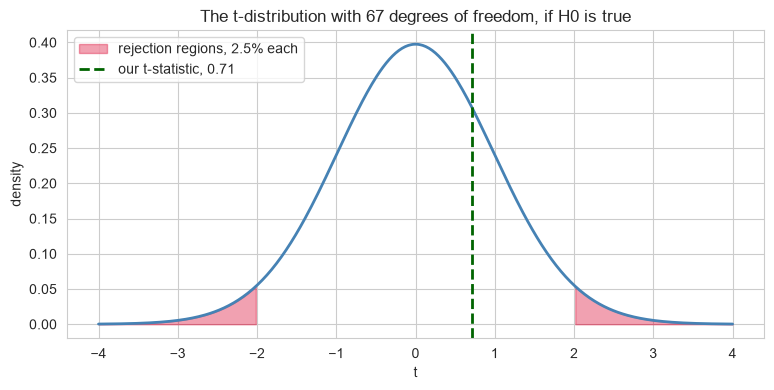

In [6]:
x = np.linspace(-4, 4, 400)
y = stats.t.pdf(x, df=dof)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(x, y, color="steelblue", linewidth=2)

# the rejection regions: results surprising enough to abandon H0
ax.fill_between(x, y, where=(x <= -t_crit), color="crimson", alpha=0.4,
                label=f"rejection regions, {alpha / 2:.1%} each")
ax.fill_between(x, y, where=(x >= t_crit), color="crimson", alpha=0.4)

# where our sample landed
ax.axvline(t_stat, color="darkgreen", linestyle="--", linewidth=2,
           label=f"our t-statistic, {t_stat:.2f}")

ax.set_title(f"The t-distribution with {dof} degrees of freedom, if H0 is true")
ax.set_xlabel("t")
ax.set_ylabel("density")
ax.legend(loc="upper left")
plt.show()

Our t-statistic lands in the middle of the curve, nowhere near the red tails. If the field
guide is right, a result like ours is entirely ordinary.

## 4. The p-value is an area

The picture already gives the verdict, but a test reports it as a single number, the
**p-value**:

> **The p-value is the probability of a result at least as extreme as ours, if the null
> hypothesis is true.**

*At least as extreme* means at least 0.71 standard errors from the claim, in **either**
direction, because $H_1$ said "different", not "heavier". So the p-value is the area under
the curve beyond $+0.71$, plus the area beyond $-0.71$. Notebook 01 showed how to get an area
beyond a value, `1 - cdf`, and the two tails are the same size:

In [7]:
# area beyond |t| in one tail, doubled for the two tails
p_value = 2 * (1 - stats.t.cdf(abs(t_stat), df=dof))
print(f"p-value: {p_value:.3f}")

p-value: 0.480


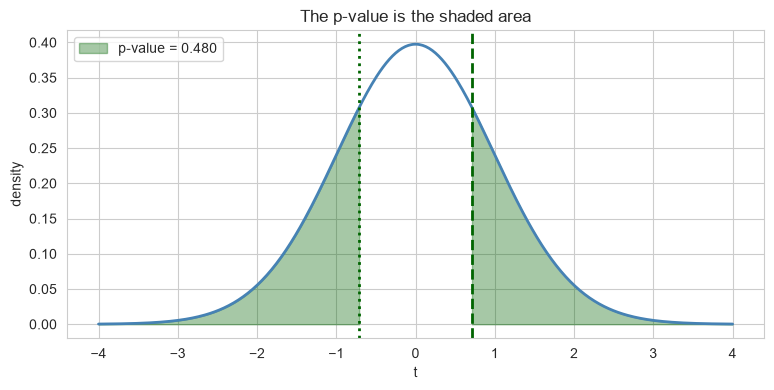

In [8]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(x, y, color="steelblue", linewidth=2)

# the p-value: everything at least as far from 0 as our t-statistic
ax.fill_between(x, y, where=(x >= abs(t_stat)), color="darkgreen", alpha=0.35,
                label=f"p-value = {p_value:.3f}")
ax.fill_between(x, y, where=(x <= -abs(t_stat)), color="darkgreen", alpha=0.35)
ax.axvline(t_stat, color="darkgreen", linestyle="--", linewidth=2)
ax.axvline(-t_stat, color="darkgreen", linestyle=":", linewidth=2)

ax.set_title("The p-value is the shaded area")
ax.set_xlabel("t")
ax.set_ylabel("density")
ax.legend(loc="upper left")
plt.show()

The p-value is 0.48. In words: **if Chinstraps really averaged 3,700 g, 48 per cent of
expeditions like ours would find a gap at least as large as 33 g.** Nothing surprising
about our sample at all.

### The decision

The rule is short: compare the p-value with $\alpha$.

- $p < \alpha$: the data would be surprising under $H_0$. **Reject** $H_0$.
- $p \geq \alpha$: it would not. **Fail to reject** $H_0$.

Both pictures above show the same decision. The p-value is below 0.05 exactly when the
t-statistic lands in a red tail.

In [9]:
if p_value < alpha:
    print(f"p = {p_value:.3f} < {alpha}: reject H0")
else:
    print(f"p = {p_value:.3f} >= {alpha}: fail to reject H0")

p = 0.480 >= 0.05: fail to reject H0


We **fail to reject** the null hypothesis: our data gives no evidence that the field guide
is wrong.

Mind the wording. We did not show that Chinstraps average exactly 3,700 g, and we must not
say we *accepted* it. A courtroom verdict of *not guilty* is not a verdict of *innocent*;
it says only that the evidence was not strong enough. Our 68 penguins are equally
consistent with a true average of 3,690 g or 3,760 g.

And now the meaning of $\alpha$. Suppose $H_0$ really is true. Then 5 per cent of samples
still land in a red tail by bad luck, and the test rejects a true null hypothesis. So
**$\alpha$ is the false-alarm rate you agreed to**, and choosing 0.05 means accepting that
one test in twenty on pure noise will cry wolf. That fact returns with force in notebook 04.

| | $H_0$ is true | $H_0$ is false |
| :--- | :--- | :--- |
| **Reject $H_0$** | false alarm, a *type I error*, probability $\alpha$ | correct |
| **Fail to reject** | correct | missed effect, a *type II error* |

## 5. The same test in one line

Everything in sections 2 to 4 is what `scipy.stats.ttest_1samp` does: a **one-sample
t-test**, comparing one sample's average with a claimed value.

In [10]:
result = stats.ttest_1samp(mass, popmean=mu_0)
print(f"t-statistic: {result.statistic:.3f}")
print(f"p-value    : {result.pvalue:.3f}")

t-statistic: 0.710
p-value    : 0.480


The same t-statistic and the same p-value as by hand. From here on you will use the one
line, but you now know what it computes, and that is what lets you interpret it.

### The test and the interval always agree

In notebook 02, 3,700 g was inside the 95 per cent confidence interval, and here the test
fails to reject 3,700 g at $\alpha = 0.05$. That is not a coincidence. The interval is
**exactly the set of claims the test would not reject**. Check it on a range of claims:

In [11]:
# the 95% confidence interval from notebook 02
ci_lower, ci_upper = stats.t.interval(0.95, df=dof, loc=mean_mass, scale=se_mass)
print(f"95% confidence interval: {ci_lower:.0f} g to {ci_upper:.0f} g\n")

for claim in [3600, 3625, 3650, 3700, 3800, 3825, 3850]:
    p = stats.ttest_1samp(mass, popmean=claim).pvalue
    inside = ci_lower <= claim <= ci_upper
    print(f"claim {claim} g: p = {p:.3f}, "
          f"{'fail to reject' if p >= alpha else 'reject'}, "
          f"{'inside' if inside else 'outside'} the interval")

95% confidence interval: 3640 g to 3826 g

claim 3600 g: p = 0.006, reject, outside the interval
claim 3625 g: p = 0.023, reject, outside the interval
claim 3650 g: p = 0.079, fail to reject, inside the interval
claim 3700 g: p = 0.480, fail to reject, inside the interval
claim 3800 g: p = 0.156, fail to reject, inside the interval
claim 3825 g: p = 0.053, fail to reject, inside the interval
claim 3850 g: p = 0.015, reject, outside the interval


Every claim inside the interval has $p \geq 0.05$, and every claim outside has $p < 0.05$.
A confidence interval and a test are two views of the same calculation: the interval says
*which values are plausible*, the test says *whether one particular value is*.

> **Exercise:**
>
> A second source claims that Chinstrap flippers average **200 mm**.
>
> 1. Write down $H_0$ and $H_1$.
> 2. Compute the t-statistic and the two-tailed p-value **by hand**, as in sections 2 to 4.
> 3. Check both with `stats.ttest_1samp`.
> 4. State your decision at $\alpha = 0.05$ in one sentence a non-statistician would
>    understand.

Your hypotheses here:

In [18]:
# your code: the t-statistic and p-value by hand
flipper = chinstrap["flipper_length_mm"]
mu_flipper = 200

n_f = len(flipper)
se_f = flipper.std() / np.sqrt(n_f)

t_flipper = (flipper.mean() - mu_flipper) / se_f
p_flipper = 2 * (1 - stats.t.cdf(abs(t_flipper), df=n_f - 1))

print(f"sample average: {flipper.mean():.1f} mm, standard error: {se_f:.2f} mm")
print(f"t-statistic   : {t_flipper:.2f}")
print(f"p-value       : {p_flipper:.2g}")

sample average: 195.8 mm, standard error: 0.86 mm
t-statistic   : -4.83
p-value       : 8.3e-06


In [20]:
# your code: the same test with scipy
result_flipper = stats.ttest_1samp(flipper, popmean=mu_flipper)
print(f"t-statistic: {result_flipper.statistic:.2f}")
print(f"p-value    : {result_flipper.pvalue:.2g}")

t-statistic: -4.83
p-value    : 8.3e-06


## 6. One tail or two?

So far $H_1$ said *different*, and a surprise in either direction counted. Sometimes the
question only has one direction. A field guide might claim that Gentoo penguins weigh **more
than 5,000 g** on average; then only a heavy sample is evidence for it, and a light one is
not.

That is a **one-tailed test**. All 5 per cent of the rejection region moves into one tail,
and the p-value becomes the area in that tail alone. In scipy you say which tail with
`alternative`: `"greater"`, `"less"`, or the default, `"two-sided"`.

In [23]:
# the Chinstrap test again, asking only "heavier than 3,700 g?"
two_tailed = stats.ttest_1samp(mass, popmean=mu_0)
one_tailed = stats.ttest_1samp(mass, popmean=mu_0, alternative="greater")
print(f"two-tailed p-value: {two_tailed.pvalue:.3f}")
print(f"one-tailed p-value: {one_tailed.pvalue:.3f}")

#Your conclusion here

#The sample average (195.8 mm) is almost 5 standard error

two-tailed p-value: 0.480
one-tailed p-value: 0.240


The one-tailed p-value is exactly half the two-tailed one, because it counts one tail
instead of two. That makes a one-tailed test easier to pass, and that is its danger.

> **Warning.** Choose the tail from the **question**, before you see the data. Picking it
> afterwards because the sample happened to come out heavy is a quiet way of halving your
> p-value, and results found that way do not hold up.

> **Exercise:**
>
> Test the claim about Gentoo penguins, using the 123 with a recorded body mass.
>
> 1. Run the two-tailed test of $\mu = 5{,}000$ g, and the one-tailed test of
>    $\mu > 5{,}000$ g.
> 2. At $\alpha = 0.05$, what does each one conclude?
> 3. Which one answers the field guide's claim, and why is it *not* acceptable to run the
>    two-tailed test first and switch when it fails?

In [25]:
# your code: two-tailed and one-tailed tests for Gentoo body mass
two_g = stats.ttest_1samp(gentoo_mass, popmean=5000)
one_g = stats.ttest_1samp(gentoo_mass, popmean=5000, alternative="greater")

print(f"Gentoo average: {gentoo_mass.mean():.0f} g (n = {len(gentoo_mass)})")
print(f"two-tailed: t = {two_g.statistic:.2f}, p = {two_g.pvalue:.3f}")
print(f"one-tailed: t = {one_g.statistic:.2f}, p = {one_g.pvalue:.3f}")

Gentoo average: 5076 g (n = 123)
two-tailed: t = 1.67, p = 0.097
one-tailed: t = 1.67, p = 0.049


Your answer to question 3 here:

## 7. From one group to two

Most questions in an analysis do not compare a group with a claimed number, but **two
groups with each other**. Do Adelie and Chinstrap penguins weigh the same? The logic does
not change at all:

- $H_0$: the two species have the same average mass, the difference is zero.
- The test statistic is the difference between the two sample averages, divided by *its*
  standard error.
- The p-value is again an area under a t-distribution.

The test is the **two-sample t-test**, `stats.ttest_ind`. The option `equal_var=False` makes
it **Welch's t-test**, which does not assume the two groups spread equally; it is the safe
default, and notebook 04 says more about why.

In [16]:
adelie_mass = df_penguins.loc[df_penguins["species"] == "Adelie", "body_mass_g"].dropna()
gentoo_mass = df_penguins.loc[df_penguins["species"] == "Gentoo", "body_mass_g"].dropna()

for name, other in [("Chinstrap", mass), ("Gentoo", gentoo_mass)]:
    result = stats.ttest_ind(adelie_mass, other, equal_var=False)
    print(f"Adelie ({adelie_mass.mean():.0f} g) vs {name} ({other.mean():.0f} g): "
          f"p = {result.pvalue:.3g}")

Adelie (3701 g) vs Chinstrap (3733 g): p = 0.588
Adelie (3701 g) vs Gentoo (5076 g): p = 7.71e-65


Adelie and Chinstrap penguins differ by about 30 g, and $p = 0.59$: no evidence of any
difference. Adelie and Gentoo penguins differ by well over a kilogram, and the p-value is
so small that it is written in powers of ten. You saw both facts in the histogram at the
end of notebook 01; now each one comes with a number that says how far chance could explain
it.

That is the step notebook 04 takes: from penguins to any pair of columns in an exploratory
analysis.

## 8. The false-alarm rate, by simulation

Section 4 claimed that at $\alpha = 0.05$ a test rejects a **true** null hypothesis 5 per
cent of the time. As in notebook 02, a pretend population lets you check it, because you
decide what is true.

> **Exercise:**
>
> Create a pretend population in which the null hypothesis is **true**: Chinstraps really
> average 3,700 g, with standard deviation 384 g.
>
> 1. Draw 1,000 samples of 68 penguins from it.
> 2. Test each sample against $\mu_0 = 3{,}700$ g with `stats.ttest_1samp`.
> 3. Count how many p-values fall below 0.05.
>
> Now imagine an analyst who runs 20 different tests on data where nothing is going on.
> How many "significant" results should they expect?

<details><summary>
Click here for a hint...
</summary>

`rng.normal(loc=3700, scale=384, size=(1000, 68))` draws all 1,000 samples at once, one per
row. `stats.ttest_1samp(samples, popmean=3700, axis=1)` then tests every row in one call,
and `.pvalue` holds all 1,000 p-values.
</details>

In [26]:
rng = np.random.default_rng(7)

# your code: 1,000 samples where H0 is true, one test each, and the share of p < 0.05
samples = rng.normal(loc=3700, scale=384, size=(1000, 68))
p_values = stats.ttest_1samp(samples, popmean=3700, axis=1).pvalue

false_alarms = (p_values < 0.05).sum()
print(f"{false_alarms} of 1,000 tests rejected a true H0 ({false_alarms / 1000:.1%})")
print(f"20 tests on pure noise: about {20 * 0.05:.0f} 'significant' result expected")

60 of 1,000 tests rejected a true H0 (6.0%)
20 tests on pure noise: about 1 'significant' result expected


## Wrapping up

In this notebook you ran a hypothesis test from first principles:

1. **Hypotheses.** $H_0$, the boring explanation, and $H_1$, what you would conclude
   instead, both about the population.
2. **Significance level.** $\alpha = 0.05$, chosen in advance: the false-alarm rate you
   accept.
3. **Test statistic.** How many standard errors the sample is from $H_0$.
4. **p-value.** The area beyond it under the t-distribution: how surprising the data is
   if $H_0$ is true.
5. **Decision.** Reject if $p < \alpha$; otherwise fail to reject, which is not the same as
   proving $H_0$.

Every test you meet follows these five steps. Only the test statistic and its
curve change, and scipy handles both. You also saw that a test and a confidence interval
always agree, that the tail has to be chosen before the data is seen, and that the same logic
compares two groups.

Next, `04_hypothesis_testing_for_eda.ipynb` puts this to work where you need it most: on
the patterns an exploratory analysis turns up.

## References & Further Reading

- [**scipy.stats.ttest_1samp**](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_1samp.html):
  The one-sample t-test, including the `alternative` argument from section 6.
- [**scipy.stats.ttest_ind**](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html):
  The two-sample t-test from section 7; `equal_var=False` gives Welch's version.
- [**StatQuest: Hypothesis Testing and The Null Hypothesis**](https://www.youtube.com/watch?v=0oc49DyA3hU):
  Section 1 in fifteen minutes.
- [**StatQuest: p-values, what they are and how to interpret them**](https://www.youtube.com/watch?v=vemZtEM63GY):
  What a p-value does and does not tell you.
- [**ModernDive: Hypothesis Testing**](https://moderndive.com/v2/hypothesis-testing.html):
  The same logic built by simulation instead of formulas.